# EDA & Preprocessing — Palmer Penguins
**Course:** Programming for AI | **Assignment:** Exploratory Data Analysis (EDA) Using Python

**Dataset:** Palmer Penguins (`penguins.csv`, 344 observations of 3 penguin species from the Palmer Archipelago, Antarctica).
The CSV is the original, uncleaned Palmer Penguins table (same data as the Hugging Face `SIH/palmer-penguins` dataset, obtained from the `seaborn-data` repository).

Every task below contains code, executed output, and a short written interpretation.

## Task 1 — Load and Understand the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os
warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid')

df = pd.read_csv('penguins.csv')
raw = df.copy()          # untouched copy for before/after comparisons

In [2]:
print("First five records"); display(df.head())
print("Last five records");  display(df.tail())

First five records


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Last five records


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,MALE


In [3]:
print("Rows, Columns:", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:"); print(df.dtypes)
df.info()

Rows, Columns: (344, 7)

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

Data types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [4]:
print("Numerical summary"); display(df.describe())
print("Categorical summary"); display(df.describe(include=['object','string']))

Numerical summary


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Categorical summary


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,MALE
freq,152,168,168


**Interpretation.** The dataset has **344 rows and 7 columns**: three categorical columns (`species`, `island`, `sex`) and four numeric measurements (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Each row is one penguin. The numeric columns have 342 non-null values and `sex` has 333, so some values are missing. Average body mass is about 4,200 g and flipper length about 201 mm. Three species and three islands are present, with Adelie the most frequent species.

## Task 2 — Identify and Handle Missing Values

In [5]:
missing = df.isnull().sum()
report_before = pd.DataFrame({'missing_count': missing,
                              'missing_percent': (missing/len(df)*100).round(2)})
print("BEFORE handling"); display(report_before)
print("Total missing cells:", int(missing.sum()),
      "| as % of all cells:", round(missing.sum()/df.size*100, 2), "%")
print("Rows with at least one missing value:", int(df.isnull().any(axis=1).sum()))
display(df[df.isnull().any(axis=1)])

BEFORE handling


,missing_count,missing_percent
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20


Total missing cells: 19 | as % of all cells: 0.79 %
Rows with at least one missing value: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


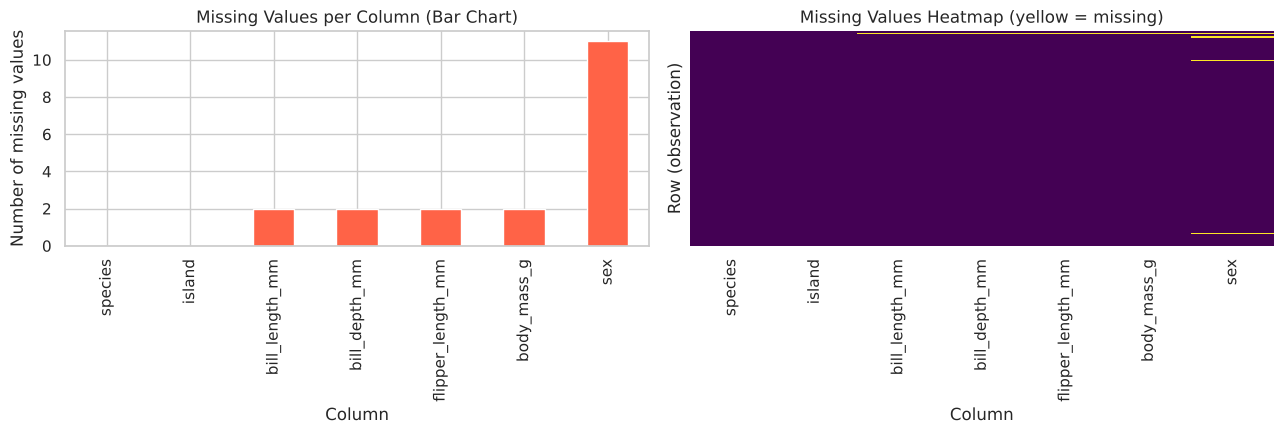

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
report_before['missing_count'].plot(kind='bar', color='tomato', ax=ax[0])
ax[0].set_title('Missing Values per Column (Bar Chart)')
ax[0].set_xlabel('Column'); ax[0].set_ylabel('Number of missing values')
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=ax[1])
ax[1].set_title('Missing Values Heatmap (yellow = missing)')
ax[1].set_xlabel('Column'); ax[1].set_ylabel('Row (observation)')
plt.tight_layout(); plt.savefig('figures/task2_missing_values.png', dpi=150); plt.show()

In [7]:
# Numerical columns -> median (computed within each species, see justification)
num_cols = ['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']
for c in num_cols:
    df[c] = df[c].fillna(df.groupby('species')[c].transform('median'))

# Categorical column -> mode
sex_mode = df['sex'].mode()[0]
print("Mode of sex:", sex_mode)
df['sex'] = df['sex'].fillna(sex_mode)

report_after = pd.DataFrame({'missing_count': df.isnull().sum(),
                             'missing_percent': (df.isnull().sum()/len(df)*100).round(2)})
print("BEFORE vs AFTER")
display(pd.concat([report_before.add_prefix('before_'), report_after.add_prefix('after_')], axis=1))

Mode of sex: MALE
BEFORE vs AFTER


,before_missing_count,before_missing_percent,after_missing_count,after_missing_percent
species,0,0.00,0,0.0
island,0,0.00,0,0.0
bill_length_mm,2,0.58,0,0.0
bill_depth_mm,2,0.58,0,0.0
flipper_length_mm,2,0.58,0,0.0
body_mass_g,2,0.58,0,0.0
sex,11,3.20,0,0.0


**Interpretation & justification.** 4 numeric columns each miss 2 values (0.58%) and `sex` misses 11 (3.20%); in total 13 rows are affected (2 rows are missing every measurement). I used the **median** for numeric columns because it is not pulled by extreme values, so it is a safe typical value; I computed it **per species** because the three species differ strongly in size (e.g. Gentoo are much heavier), so one global value would be biased. I used the **mode** for `sex` because it is categorical and has no meaningful mean or median — the most frequent category is the only sensible fill. I imputed rather than dropped because the missing share is tiny and every row would otherwise be lost for the next assignment. After handling, no missing values remain. Note: imputing `sex` with the mode is a simplification and slightly biases the sex balance.

## Task 3 — Identify and Remove Duplicate Records

In [8]:
print("Duplicate rows BEFORE:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows AFTER :", df.duplicated().sum())
print("Shape after drop_duplicates:", df.shape)

Duplicate rows BEFORE: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex


Duplicate rows AFTER : 0
Shape after drop_duplicates: (344, 7)


**Interpretation.** `duplicated()` finds **0 duplicate rows**, so nothing is removed and the shape stays (344, 7). I report this honestly rather than inventing duplicates. Note that several penguins share identical measurements by chance, but a full-row match across all 7 columns would be required to count as a duplicate. Duplicates are repeated records of the same observation, which is different from missing values (absent information).

## Task 4 — Handle Inconsistent Categorical Data

In [9]:
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
print("Categorical columns:", cat_cols)
for c in cat_cols:
    print(f"\n--- {c} ---")
    print("Unique values (repr, shows stray spaces):", [repr(v) for v in df[c].unique()])
    print(df[c].value_counts())
    stray = (df[c] != df[c].str.strip()).sum()
    print("Values with leading/trailing spaces:", stray)

Categorical columns: ['species', 'island', 'sex']

--- species ---
Unique values (repr, shows stray spaces): ["'Adelie'", "'Chinstrap'", "'Gentoo'"]
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
Values with leading/trailing spaces: 0

--- island ---
Unique values (repr, shows stray spaces): ["'Torgersen'", "'Biscoe'", "'Dream'"]
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
Values with leading/trailing spaces: 0

--- sex ---
Unique values (repr, shows stray spaces): ["'MALE'", "'FEMALE'"]
sex
MALE      179
FEMALE    165
Name: count, dtype: int64
Values with leading/trailing spaces: 0


In [10]:
before = {c: df[c].unique().tolist() for c in cat_cols}
for c in cat_cols:
    df[c] = df[c].str.strip().str.title()
after = {c: df[c].unique().tolist() for c in cat_cols}
display(pd.DataFrame({'before': pd.Series(before), 'after': pd.Series(after)}))

,before,after
species,"[Adelie, Chinstrap, Gentoo]","[Adelie, Chinstrap, Gentoo]"
island,"[Torgersen, Biscoe, Dream]","[Torgersen, Biscoe, Dream]"
sex,"[MALE, FEMALE]","[Male, Female]"


**Interpretation.** There are no stray spaces and no spelling variants: `species` and `island` already use consistent capitalisation, and each category appears in only one form. The only inconsistency is style: `sex` is stored in UPPERCASE (`MALE`/`FEMALE`) while the other columns use Title case. I applied `strip()` and `title()` to every categorical column so they are uniform (`Male`/`Female`). This changes only formatting, never the meaning, and prevents a model from treating differently-cased strings as different categories.

## Task 5 — Detect and Handle Outliers

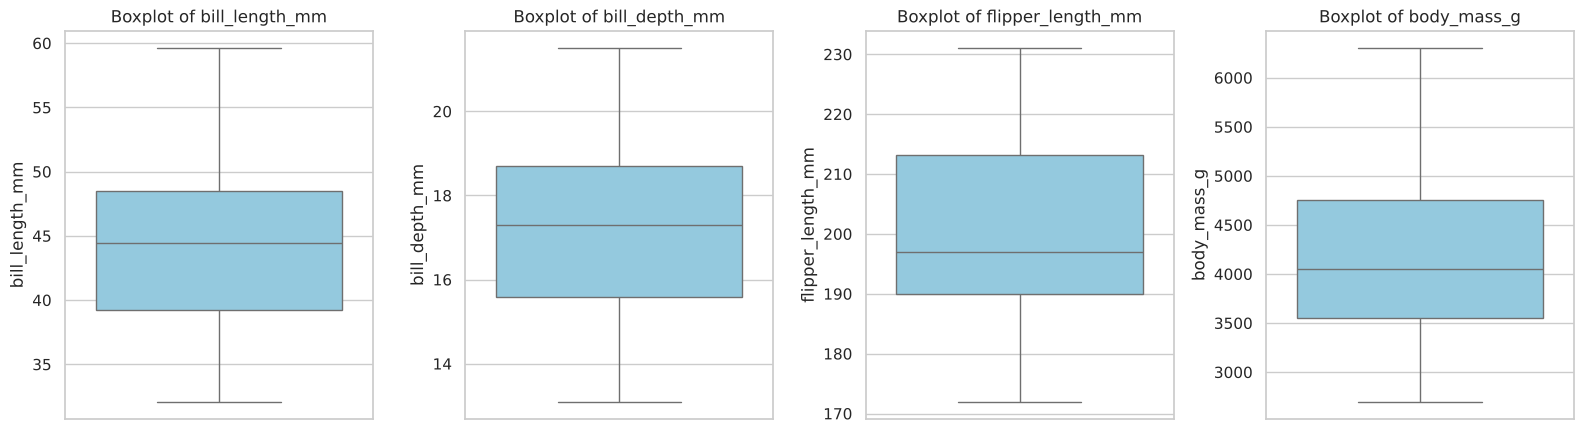

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color='skyblue')
    ax.set_title(f'Boxplot of {c}'); ax.set_ylabel(c)
plt.tight_layout(); plt.savefig('figures/task5_boxplots.png', dpi=150); plt.show()

In [12]:
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = df[(df[c] < lo) | (df[c] > hi)]
    rows.append([c, q1, q3, iqr, lo, hi, len(out)])
iqr_table = pd.DataFrame(rows, columns=['column','Q1','Q3','IQR','lower_bound','upper_bound','n_outliers'])
display(iqr_table.round(2))

# Check within species too, because species differ greatly in size
print("Outliers when checked within each species:")
found = False
for sp, g in df.groupby('species'):
    for c in num_cols:
        q1, q3 = g[c].quantile([.25, .75]); i = q3 - q1
        o = g[(g[c] < q1-1.5*i) | (g[c] > q3+1.5*i)]
        if len(o):
            found = True; print(f"\n{sp} - {c}"); display(o)
if not found: print("None")

,column,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers
0,bill_length_mm,39.20,48.50,9.30,25.25,62.45,0
1,bill_depth_mm,15.58,18.70,3.12,10.89,23.39,0
2,flipper_length_mm,190.00,213.25,23.25,155.12,248.12,0
3,body_mass_g,3550.00,4756.25,1206.25,1740.62,6565.62,0


Outliers when checked within each species:

Adelie - bill_depth_mm


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
19,Adelie,Torgersen,46.0,21.5,194.0,4200.0,Male



Adelie - flipper_length_mm


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
28,Adelie,Biscoe,37.9,18.6,172.0,3150.0,Female
129,Adelie,Torgersen,44.1,18.0,210.0,4000.0,Male



Chinstrap - body_mass_g


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
189,Chinstrap,Dream,52.0,20.7,210.0,4800.0,Male
190,Chinstrap,Dream,46.9,16.6,192.0,2700.0,Female



Gentoo - bill_length_mm


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
321,Gentoo,Biscoe,55.9,17.0,228.0,5600.0,Male


**Interpretation & decision.** Using the 1.5×IQR rule on the whole dataset, **no value in any of the four numeric columns lies outside the bounds** (see table). Checking within each species flags only 7 mild points (Adelie bill depth 21.5 mm and flipper lengths 172/210 mm; Chinstrap body mass 2,700/4,800 g; Gentoo bill length 55.9/59.6 mm). All are physically plausible individuals (small or large birds of that species), not measurement errors, and none is impossible (nothing negative or absurdly large). I therefore **retain all values**: removing them would shrink a small dataset and discard real biological variation. No capping was needed.

## Task 6 — Data Visualization

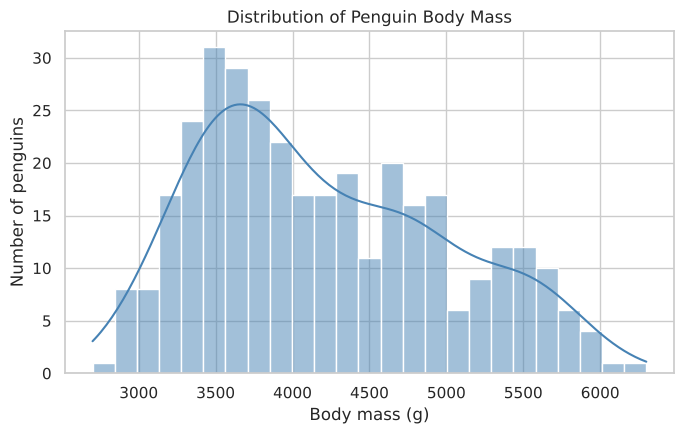

In [13]:
plt.figure(figsize=(7,4.5))
sns.histplot(df['body_mass_g'], bins=25, kde=True, color='steelblue')
plt.title('Distribution of Penguin Body Mass'); plt.xlabel('Body mass (g)'); plt.ylabel('Number of penguins')
plt.tight_layout(); plt.savefig('figures/task6_histogram.png', dpi=150); plt.show()

**Interpretation.** Body mass is right-skewed with two humps: a main group around 3,500–4,000 g (Adelie/Chinstrap) and a second group near 5,000 g (the larger Gentoo), so the mixture of species creates the multi-modal shape.

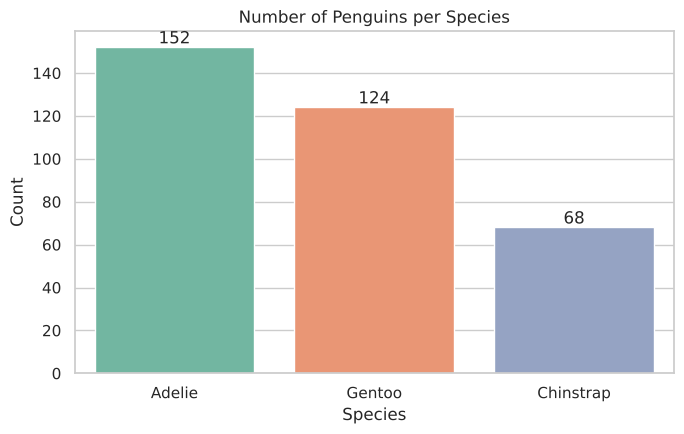

In [14]:
plt.figure(figsize=(7,4.5))
ax = sns.countplot(data=df, x='species', palette='Set2', order=df['species'].value_counts().index)
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Number of Penguins per Species'); plt.xlabel('Species'); plt.ylabel('Count')
plt.tight_layout(); plt.savefig('figures/task6_barchart.png', dpi=150); plt.show()

**Interpretation.** Adelie is the most common species (152), followed by Gentoo (124) and Chinstrap (68). The classes are moderately imbalanced, which is worth remembering when building a classifier.

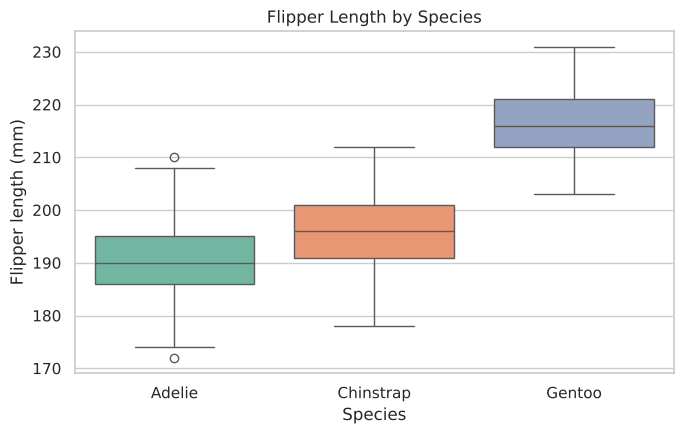

In [15]:
plt.figure(figsize=(7,4.5))
sns.boxplot(data=df, x='species', y='flipper_length_mm', palette='Set2')
plt.title('Flipper Length by Species'); plt.xlabel('Species'); plt.ylabel('Flipper length (mm)')
plt.tight_layout(); plt.savefig('figures/task6_boxplot.png', dpi=150); plt.show()

**Interpretation.** Gentoo penguins have clearly longer flippers (median ≈ 216 mm) than Adelie and Chinstrap (≈ 190–196 mm). Boxes barely overlap, so flipper length separates Gentoo well, and no extreme outliers appear within species.

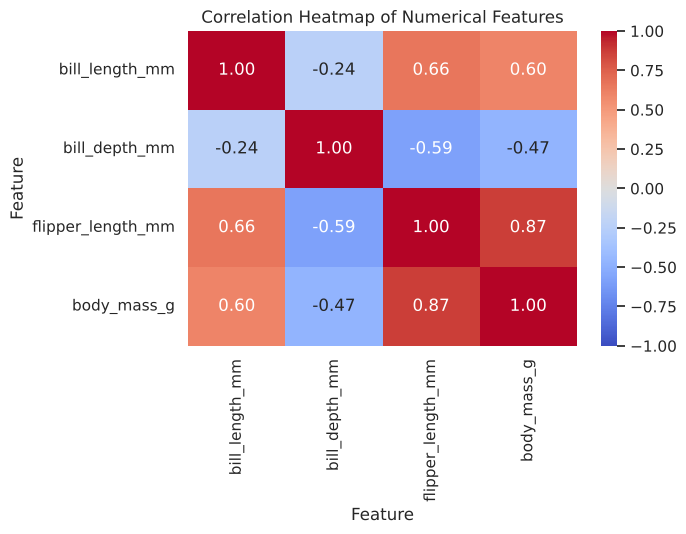

In [16]:
plt.figure(figsize=(7,5.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numerical Features'); plt.xlabel('Feature'); plt.ylabel('Feature')
plt.tight_layout(); plt.savefig('figures/task6_heatmap.png', dpi=150); plt.show()

**Interpretation.** Flipper length and body mass are strongly positively correlated (≈ 0.87), and bill length also relates positively to mass and flipper length. Bill depth is *negatively* correlated with flipper length and mass overall — a hint of Simpson's paradox, explored in the extra scatter plot below.

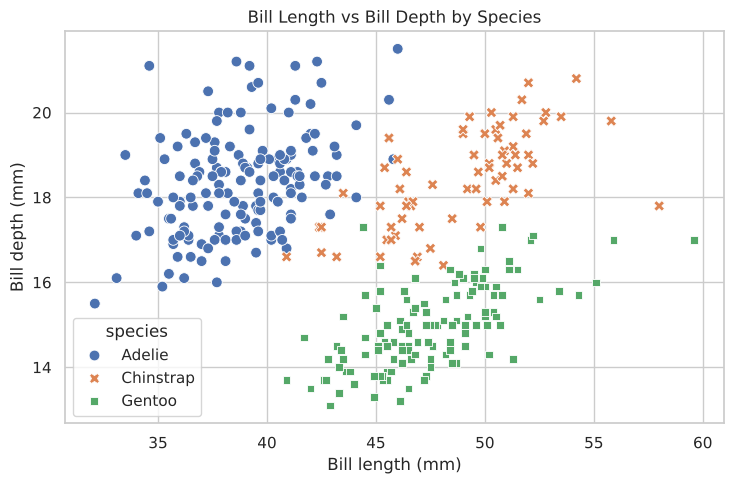

In [17]:
plt.figure(figsize=(7.5,5))
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', hue='species', style='species', s=60)
plt.title('Bill Length vs Bill Depth by Species'); plt.xlabel('Bill length (mm)'); plt.ylabel('Bill depth (mm)')
plt.tight_layout(); plt.savefig('figures/task6_scatter_extra.png', dpi=150); plt.show()

**Interpretation (extra).** Overall the trend looks negative, but within each species bill length and depth rise together. The three species form separate clusters, so a combination of features should distinguish species well.

## Task 7 — Feature Engineering

,bill_length_mm,bill_depth_mm,bill_ratio
0,39.1,18.7,2.090909
1,39.5,17.4,2.270115
2,40.3,18.0,2.238889
3,38.8,18.4,2.108696
4,36.7,19.3,1.901554


           count  mean   std   min   25%   50%   75%   max
species                                                   
Adelie     152.0  2.12  0.15  1.64  2.01  2.13  2.24  2.45
Chinstrap   68.0  2.65  0.15  2.35  2.56  2.66  2.73  3.26
Gentoo     124.0  3.18  0.17  2.57  3.07  3.16  3.28  3.61


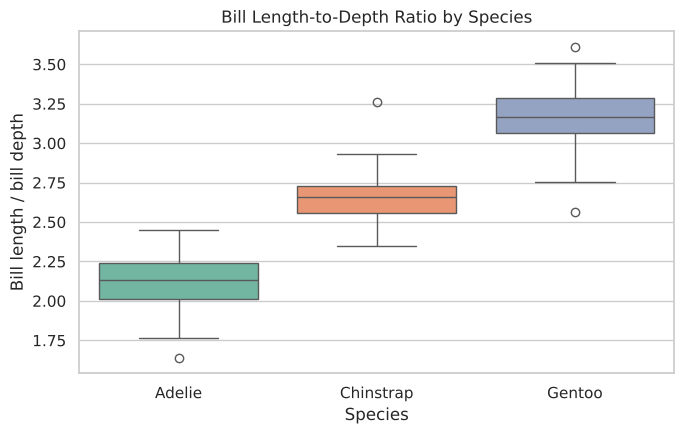

In [18]:
df['bill_ratio'] = df['bill_length_mm'] / df['bill_depth_mm']
df['body_mass_kg'] = df['body_mass_g'] / 1000
display(df[['bill_length_mm','bill_depth_mm','bill_ratio']].head())
print(df.groupby('species')['bill_ratio'].describe().round(2))
plt.figure(figsize=(7,4.5))
sns.boxplot(data=df, x='species', y='bill_ratio', palette='Set2')
plt.title('Bill Length-to-Depth Ratio by Species'); plt.xlabel('Species'); plt.ylabel('Bill length / bill depth')
plt.tight_layout(); plt.savefig('figures/task7_bill_ratio.png', dpi=150); plt.show()

**Justification.** `bill_ratio` = bill length ÷ bill depth describes the *shape* of the bill rather than its size. The plot and group statistics show clearly different medians — Adelie ≈ 2.13, Chinstrap ≈ 2.66, Gentoo ≈ 3.16 — so the ratio separates all three species with little overlap, which means it adds discriminating information beyond the two raw columns and partly cancels overall body size. A model can use one such feature more easily than learning the interaction from two separate columns. `body_mass_kg` is just a unit conversion (kept for readability; it is redundant and can be dropped).

## Task 8 — Encode Categorical Variables

In [19]:
print("Categorical columns:", df.select_dtypes(exclude='number').columns.tolist())
print("BEFORE encoding"); display(df[['species','island','sex']].head())

Categorical columns: ['species', 'island', 'sex']
BEFORE encoding


,species,island,sex
0,Adelie,Torgersen,Male
1,Adelie,Torgersen,Female
2,Adelie,Torgersen,Female
3,Adelie,Torgersen,Male
4,Adelie,Torgersen,Female


In [20]:
from sklearn.preprocessing import LabelEncoder

# Label encoding: sex (binary: Female=0, Male=1)
le = LabelEncoder()
df['sex_encoded'] = le.fit_transform(df['sex'])
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# One-hot encoding: island (nominal, no order)
df_enc = pd.get_dummies(df, columns=['island'], prefix='island', dtype=int)

print("AFTER encoding")
display(df_enc[['species','sex','sex_encoded'] + [c for c in df_enc.columns if c.startswith('island_')]].head(8))

Label mapping: {'Female': np.int64(0), 'Male': np.int64(1)}
AFTER encoding


,species,sex,sex_encoded,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,Male,1,0,0,1
1,Adelie,Female,0,0,0,1
2,Adelie,Female,0,0,0,1
3,Adelie,Male,1,0,0,1
4,Adelie,Female,0,0,0,1
5,Adelie,Male,1,0,0,1
6,Adelie,Female,0,0,0,1
7,Adelie,Male,1,0,0,1


**Rationale.** *Label encoding for `sex`:* it has only two categories, so mapping them to 0/1 is lossless and introduces no false ordering. *One-hot encoding for `island`:* it is nominal (Biscoe, Dream and Torgersen have no natural order), so separate 0/1 columns avoid implying that one island is "greater" than another. `species` is left as a readable label because it is the likely target for the next assignment and does not need to be encoded here.

## Task 9 — Feature Scaling

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scale_cols = ['bill_length_mm', 'flipper_length_mm', 'body_mass_g']   # target (species) excluded
X = df_enc.drop(columns=['species'])
y = df_enc['species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

mm, ss = MinMaxScaler(), StandardScaler()
mm_train = pd.DataFrame(mm.fit_transform(X_train[scale_cols]), columns=scale_cols, index=X_train.index)  # fit on TRAIN only
ss_train = pd.DataFrame(ss.fit_transform(X_train[scale_cols]), columns=scale_cols, index=X_train.index)
mm_test  = pd.DataFrame(mm.transform(X_test[scale_cols]), columns=scale_cols, index=X_test.index)
ss_test  = pd.DataFrame(ss.transform(X_test[scale_cols]), columns=scale_cols, index=X_test.index)

comparison = pd.concat([X_train[scale_cols].add_suffix('_original'),
                        mm_train.add_suffix('_minmax'),
                        ss_train.add_suffix('_standard')], axis=1).round(3)
print("Comparison table (first 8 training rows)")
display(comparison[[f'{c}_{s}' for c in scale_cols for s in ('original','minmax','standard')]].head(8))

stats = pd.DataFrame({
  'orig_min': X_train[scale_cols].min(), 'orig_max': X_train[scale_cols].max(),
  'minmax_min': mm_train.min(), 'minmax_max': mm_train.max(),
  'std_mean': ss_train.mean().round(3), 'std_std': ss_train.std(ddof=0).round(3)})
display(stats.round(3))

Train: (275, 11) Test: (69, 11)
Comparison table (first 8 training rows)


,bill_length_mm_original,bill_length_mm_minmax,bill_length_mm_standard,flipper_length_mm_original,flipper_length_mm_minmax,flipper_length_mm_standard,body_mass_g_original,body_mass_g_minmax,body_mass_g_standard
98,33.1,0.000,-1.999,178.0,0.102,-1.641,2900.0,0.056,-1.634
114,39.6,0.245,-0.814,191.0,0.322,-0.708,3900.0,0.333,-0.389
118,35.7,0.098,-1.525,189.0,0.288,-0.851,3350.0,0.181,-1.073
303,50.0,0.638,1.083,224.0,0.881,1.661,5350.0,0.736,1.416
343,49.9,0.634,1.065,213.0,0.695,0.871,5400.0,0.750,1.478
269,45.2,0.457,0.208,215.0,0.729,1.015,5300.0,0.722,1.354
141,40.6,0.283,-0.631,187.0,0.254,-0.995,3475.0,0.215,-0.918
259,48.7,0.589,0.846,208.0,0.610,0.512,5350.0,0.736,1.416


,orig_min,orig_max,minmax_min,minmax_max,std_mean,std_std
bill_length_mm,33.1,59.6,0.0,1.0,-0.0,1.0
flipper_length_mm,172.0,231.0,0.0,1.0,-0.0,1.0
body_mass_g,2700.0,6300.0,0.0,1.0,0.0,1.0


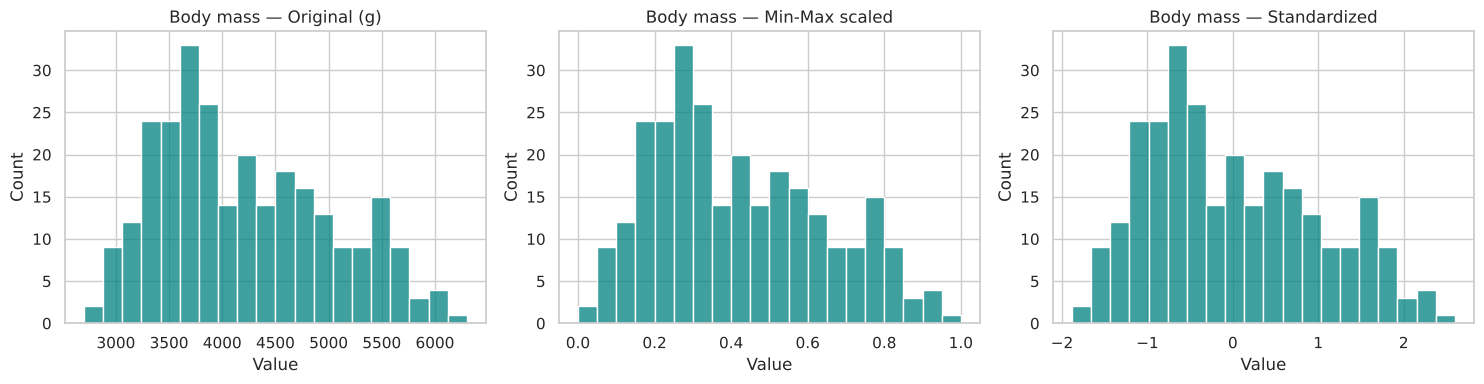

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, d, t in zip(ax, [X_train['body_mass_g'], mm_train['body_mass_g'], ss_train['body_mass_g']],
                   ['Original (g)', 'Min-Max scaled', 'Standardized']):
    sns.histplot(d, bins=20, ax=a, color='teal'); a.set_title(f'Body mass — {t}'); a.set_xlabel('Value'); a.set_ylabel('Count')
plt.tight_layout(); plt.savefig('figures/task9_scaling.png', dpi=150); plt.show()

**Explanation.** **Min-Max scaling** rescales each feature to a fixed range, here 0–1, via (x − min)/(max − min), so it preserves the shape of the distribution but is sensitive to outliers. **Standardization** rescales to mean 0 and standard deviation 1 via (x − μ)/σ and does not bound the values. Min-Max suits algorithms or inputs that expect a bounded range (neural networks, image-like data, KNN with no big outliers); standardization suits algorithms that assume centred data or are sensitive to variance (SVM, logistic regression, PCA, gradient-based models) and handles outliers better. The scalers were fitted **only on the training set** and then applied to the test set, which avoids data leakage (test values may fall slightly outside 0–1 for Min-Max, which is expected). The target `species` was excluded.

## Task 10 — Prepare and Save the Cleaned Dataset

In [23]:
final = df_enc.copy()
final = final.drop(columns=['sex'])     # replaced by sex_encoded
print("Missing values left:", int(final.isnull().sum().sum()))
print("Duplicate rows left:", int(final.duplicated().sum()))
print("Data types:"); print(final.dtypes)
display(final.head(10))
final.to_csv('penguins_cleaned.csv', index=False)
print("\nSaved penguins_cleaned.csv")
print("Final rows x columns:", final.shape)

Missing values left: 0
Duplicate rows left: 0
Data types:
species                  str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
bill_ratio           float64
body_mass_kg         float64
sex_encoded            int64
island_Biscoe          int64
island_Dream           int64
island_Torgersen       int64
dtype: object


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,bill_ratio,body_mass_kg,sex_encoded,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,39.1,18.7,181.0,3750.0,2.090909,3.750,1,0,0,1
1,Adelie,39.5,17.4,186.0,3800.0,2.270115,3.800,0,0,0,1
2,Adelie,40.3,18.0,195.0,3250.0,2.238889,3.250,0,0,0,1
3,Adelie,38.8,18.4,190.0,3700.0,2.108696,3.700,1,0,0,1
4,Adelie,36.7,19.3,193.0,3450.0,1.901554,3.450,0,0,0,1
5,Adelie,39.3,20.6,190.0,3650.0,1.907767,3.650,1,0,0,1
6,Adelie,38.9,17.8,181.0,3625.0,2.185393,3.625,0,0,0,1
7,Adelie,39.2,19.6,195.0,4675.0,2.000000,4.675,1,0,0,1
8,Adelie,34.1,18.1,193.0,3475.0,1.883978,3.475,1,0,0,1
9,Adelie,42.0,20.2,190.0,4250.0,2.079208,4.250,1,0,0,1



Saved penguins_cleaned.csv
Final rows x columns: (344, 11)


In [24]:
check = pd.read_csv('penguins_cleaned.csv')
print("Re-loaded file shape:", check.shape, "| missing:", int(check.isnull().sum().sum()))
print("Rows: raw", raw.shape[0], "-> cleaned", check.shape[0], "(no rows removed)")

Re-loaded file shape: (344, 11) | missing: 0
Rows: raw 344 -> cleaned 344 (no rows removed)


**Summary.** All cleaning steps are complete: 13 rows with missing values were imputed (median per species for numerics, mode for `sex`), 0 duplicates were found, categorical text was standardised, and 0 outliers were removed (all retained as genuine). I added `bill_ratio` and `body_mass_kg`, label-encoded `sex`, one-hot encoded `island`, and demonstrated both scalers. The saved file **`penguins_cleaned.csv`** is unscaled so that scaling can be fitted on the training split in the next assignment.

## Section 6 — Additional Questions

**1. Why is data preprocessing important before training an AI model?**
Models learn patterns from whatever data they are given. Raw data contains missing values, inconsistent formats, duplicates, and features on very different scales that many algorithms cannot handle or that mislead them. Preprocessing makes the data complete, consistent and numeric, so the model learns real patterns instead of noise (“garbage in, garbage out”).

**2. What is the difference between missing values and duplicate records?**
A missing value is a cell with no recorded information (e.g. no `sex` for a penguin), so information is absent. A duplicate record is a row repeated (the same observation stored more than once), so information is over-represented. Missing values are usually filled or dropped; duplicates are removed.

**3. Why is the median sometimes preferred over the mean when handling missing values?**
The mean is pulled by extreme values and skewed distributions, whereas the median is the middle value and is robust to outliers. For skewed data (such as income) the median is a more typical fill value and does not distort the distribution.

**4. What are outliers, and why should we not automatically remove them?**
Outliers are values that lie unusually far from most of the data (for example outside 1.5×IQR). They can be errors, but they can also be genuine rare cases (a very large penguin). Removing them blindly throws away real information, reduces the sample size and may bias the analysis, so they should be investigated first and removed or capped only if they are errors.

**5. What is the difference between Label Encoding and One-Hot Encoding?**
Label encoding converts each category into one integer (e.g. Female=0, Male=1) in a single column, which implies an order, so it suits ordinal or binary variables. One-hot encoding creates one 0/1 column per category with no implied order, so it suits nominal variables, but it increases the number of columns.

**6. Why is feature scaling important for some machine learning algorithms?**
Algorithms that use distances or gradients (KNN, SVM, k-means, logistic regression, neural networks, PCA) are dominated by features with large numeric ranges (e.g. body mass in thousands vs. bill depth in tens). Scaling puts features on a comparable range so each contributes fairly and training converges faster. Tree-based models are mostly unaffected.

**7. What problems could occur if we train a machine learning model on uncleaned data?**
The model may crash on missing values or text, learn biased or wrong patterns from errors and inconsistent labels, overweight duplicated records (and leak information between train and test), be dominated by large-scale features, and generalise poorly, giving unreliable predictions and misleading accuracy.